# Carriers: the dental example

Instance from `data/generator/dental-carriers-example.json` (carrier generator, `math/21_instance-generator.md` §4a;
model in `math/03_loads.md`). Every order has one secondary part, printed on a carrier, with one telescope per primary
part; the primary parts are milled. A carrier holds up to 12 telescopes, a print run up to 4 carriers. Nesting is
emulated in due-date order. **The durations are placeholders, not Fidentis data.**

Route of every order: design → milling of the primary parts (one operation, n × p) → print (run: setup, print,
removal on one printer) → oven → QM (per carrier, waits for the primary parts of all its orders) → saw → finish.

In [1]:
%matplotlib inline
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt

import simulation
from simulation.carrier_generator import CarrierGeneratorParams, generate_carrier_instance
from simulation.check.feasibility import check_schedule
from simulation.control.rescheduling import ReschedulingPolicy, execute
from simulation.due_dates import assign_due_dates
from simulation.io.json_loader import read_model
from simulation.metrics import run_metrics
from simulation.model.compiled import compile_instance
from simulation.objectives import MAKESPAN, TARDY_ORDERS, TOTAL_TARDINESS, lexicographic
from simulation.planners.cpsat import cpsat_planner, solve
from simulation.planners.dispatching import best_dispatch
from simulation.sim.scenario import sample_scenario
from simulation.viz import plot_carriers, plot_gantt

DATA = Path(simulation.__file__).parents[2] / "data"
params = read_model(DATA / "generator" / "dental-carriers-example.json", CarrierGeneratorParams)
inst = generate_carrier_instance(params)  # nesting in the order of the generator's due dates (lead-time bound)
# due dates relative to the best dispatching plan (theta 1, 1.2, 1.5; math/06): that plan is on time, tardiness
# comes from disturbances or weaker plans. The lead-time bound ignores the oven queue and is unreachable here.
_, reference = best_dispatch(compile_instance(inst))
inst = assign_due_dates(inst, (1.0, 1.2, 1.5), seed=0, reference=reference)
ci = compile_instance(inst)
telescopes = {o.id: sum(p.type == "primary" for p in o.parts) for o in inst.orders}
print(f"{len(inst.orders)} orders, {len(inst.carriers)} carriers, {len(inst.runs)} print runs, {ci.n_ops} operations, "
      f"{len(inst.machines)} machines")

40 orders, 16 carriers, 4 print runs, 180 operations, 12 machines


## Nesting: carriers and loads

One row per carrier, grouped by print run (the run's load, separated by lines); one segment per order, width =
telescopes of its secondary part; dashed line: capacity 12. Below: the print duration of each run from the
estimator (fixed 20 + 0.5 × summed part times, clamped to [longest part, sum]).

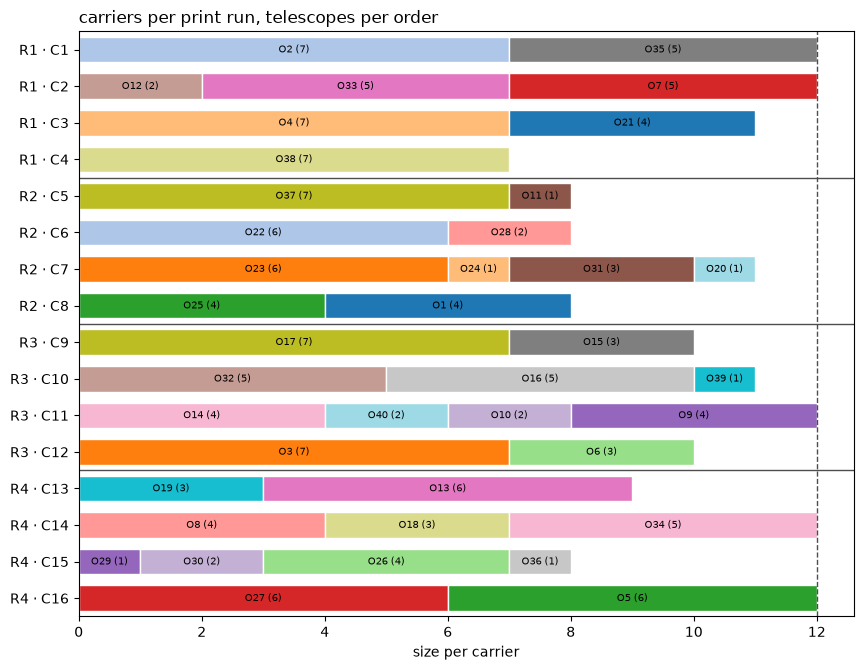

R1: carriers C1, C2, C3, C4 · 42 telescopes · print {188} min
R2: carriers C5, C6, C7, C8 · 35 telescopes · print {160} min
R3: carriers C9, C10, C11, C12 · 43 telescopes · print {192} min
R4: carriers C13, C14, C15, C16 · 41 telescopes · print {184} min


In [2]:
plot_carriers(inst, size=lambda k, _part: telescopes[k], capacity=params.carrier_capacity,
              title="carriers per print run, telescopes per order")
plt.show()
for r in inst.runs:
    load = sum(telescopes[k] for c in inst.carriers if c.id in r.carriers for k, _ in c.parts)
    print_time = dict(ci.options[ci.op_index[r.id, "print"]])
    print(f"{r.id}: carriers {', '.join(r.carriers)} · {load} telescopes · print {set(print_time.values())} min")

## Plan

Best dispatching rule and CP-SAT (60 s, warm start from the rule, one worker) for the makespan, and CP-SAT with
total tardiness first and makespan second. Gantt chart of the lexicographic plan: order operations colored by
order, carrier operations (oven, QM, saw) light grey, run operations (setup, print, removal) dark grey.

In [3]:
rule, rule_plan = best_dispatch(ci)
cp = solve(ci, time_limit=60, workers=1, hint=rule_plan)
TARDINESS_FIRST = lexicographic(TOTAL_TARDINESS, MAKESPAN)
cp_lex = solve(ci, TARDINESS_FIRST, time_limit=60, workers=1, hint=best_dispatch(ci, TARDINESS_FIRST)[1])
print(f"{'plan':28} {'status':>8} {'Cmax':>6} {'sum T':>6} {'tardy':>6} {'violations':>11}")
for name, status, plan in [(f"best rule ({rule})", "", rule_plan), ("CP-SAT makespan", cp.status, cp.schedule),
                           ("CP-SAT tardiness>makespan", cp_lex.status, cp_lex.schedule)]:
    print(f"{name:28} {status:>8} {MAKESPAN.evaluate(ci, plan):>6} {TOTAL_TARDINESS.evaluate(ci, plan):>6}"
          f" {TARDY_ORDERS.evaluate(ci, plan):>6} {len(check_schedule(ci, plan)):>11}")

plan                           status   Cmax  sum T  tardy  violations
best rule (spt/joint)                   1860      0      0           0
CP-SAT makespan               OPTIMAL   1847   2504     11           0
CP-SAT tardiness>makespan     OPTIMAL   1850      0      0           0


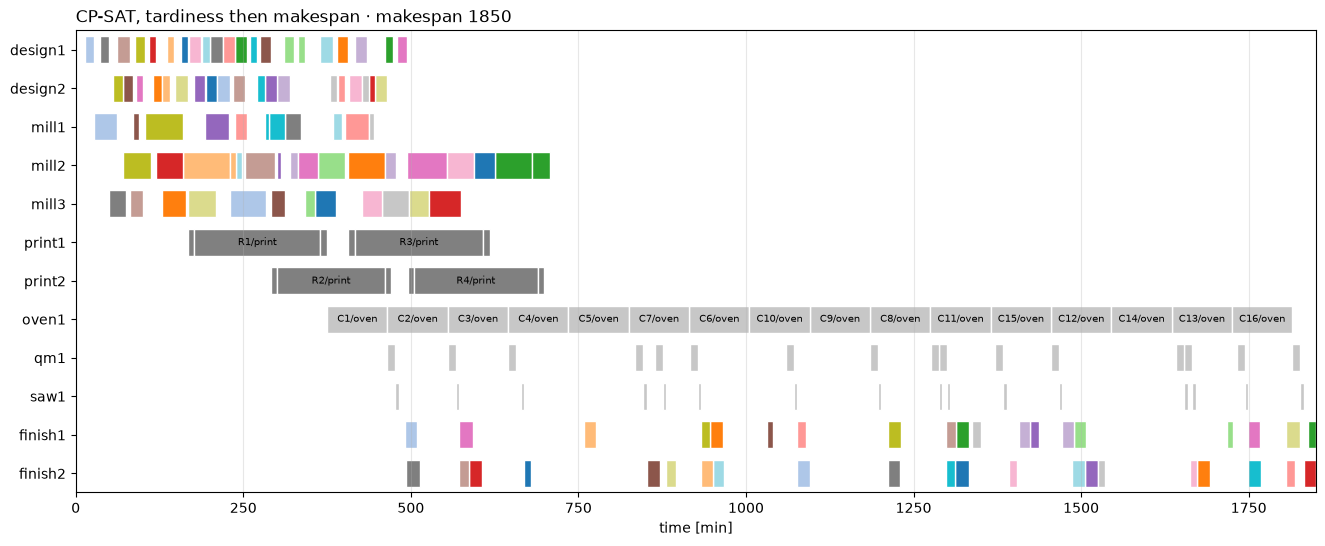

In [4]:
plot_gantt(ci, cp_lex.schedule, title=f"CP-SAT, tardiness then makespan · makespan {MAKESPAN.evaluate(ci, cp_lex.schedule)}")
plt.gcf().set_size_inches(16, 6)
plt.show()

## Execution under disturbances

Durations log-normal ($\sigma = 0.3$), start offsets ($q = 0.5$, $a = b = 5$), seeds 0–4. Start plan: the
lexicographic CP-SAT plan. Policies: no planning tool, repair only, complete rescheduling with CP-SAT (tardiness
first, 2 s per call) triggered by $\delta_C = 10$, $\delta_S = 30$ and a safety net every 120 minutes. Means over the
seeds; one run, no statistical test.

In [5]:
plan = cp_lex.schedule
scenarios = [sample_scenario(inst, sigma=0.3, seed=seed, q=0.5, max_early=5, max_late=5) for seed in range(5)]
policies = {
    "no planning tool": None,
    "repair only": ReschedulingPolicy(),
    "CP-SAT rescheduling": ReschedulingPolicy(cpsat_planner(time_limit=2, objective=TARDINESS_FIRST),
                                              max_makespan_change=10, max_shift=30, period=120),
}
print(f"{'policy':22} {'Cmax':>7} {'F':>7} {'sum T':>7} {'tardy':>6} {'D_M':>5} {'N_C':>5} {'feasible':>9}")
for name, policy in policies.items():
    results = [execute(ci, plan, s, policy) for s in scenarios]
    rows = [run_metrics(ci, plan, r) for r in results]
    ok = all({v.constraint for v in check_schedule(ci, r.schedule)} <= {"C2"} for r in results)
    avg = {key: mean(r[key] for r in rows) for key in rows[0]}
    print(f"{name:22} {avg['makespan']:>7.1f} {avg['mean_flow_time']:>7.1f} {avg['total_tardiness']:>7.1f}"
          f" {avg['tardy_orders']:>6.1f} {avg['machine_changes']:>5.1f} {avg['reschedulings']:>5.1f} {str(ok):>9}")

policy                    Cmax       F   sum T  tardy   D_M   N_C  feasible
no planning tool        1971.2  1057.3   686.4   13.6   0.0   0.0      True


repair only             1923.6  1035.9   455.0    9.8   0.0   0.0      True


CP-SAT rescheduling     1924.0  1001.3   297.8    6.6  25.0  32.6      True


**Observations** (one instance, 5 seeds, placeholder durations; own computation, no statistical test):

- **The oven is the bottleneck.** Without oven batching every carrier has its own oven operation (simplification in
  `math/03`), so the 16 carriers pass the single oven one after another (16 × 90 min); everything after the prints
  waits for it (Gantt chart). With the lead-time bound as basis, every order was late. A real oven holds several
  plates (p-batch): oven batching (next carrier step) removes most of this queue.
- **Tardiness first costs almost no makespan:** 1850 vs. the makespan optimum 1847, with no late order instead of 11.
- **Under disturbances** CP-SAT rescheduling (tardiness first) lowers the total tardiness from 455 (repair only) to
  298 and the late orders from 9.8 to 6.6, at about 25 machine changes per run.
- The nesting fills carriers to 7–12 telescopes; runs carry 35–43 telescopes, print times 160–192 min.